# DS3000 Course Project — Group 6, Lab Section 5
## Bank Customer Churn (dataset #13) · Lab Demo 1: Data understanding and baseline

**Problem statement.** A retail bank wants to know, ahead of time, which customers are likely to close their accounts, so it can target them with retention offers. From each customer's profile and account details, we predict whether they **left the bank** (`Exited = 1`) or stayed (`Exited = 0`). This is a **binary classification** task.

**Operational reading.** Missing a customer who leaves (a false negative) loses that customer's revenue. Flagging a loyal customer (a false positive) wastes a retention offer. Both errors matter, so we cannot judge models on accuracy alone.

| Item | Value |
|---|---|
| Dataset | Bank Customer Churn — Kaggle `santoshd3/bank-customers` (course pool #13) |
| Rows / columns | 10,000 customers × 14 columns |
| Target | `Exited` (1 = left the bank, 0 = stayed) |
| Task | Binary classification, imbalanced (≈ 20% positive) |

**Contents.** 0 Setup · 1 Load · 2 Data audit · 3 Feature decisions · 4 Frozen split · 5 EDA (training rows only) · 6 Preprocessing · 7 Baselines · 8 Comparison table · 9 Conclusion and open risk · 10 Smoke test and checkpoint

## 0. Setup and reproducibility

In [8]:
import time, platform, subprocess # timing models, printing versions, reading the git commit
from pathlib import Path  # file paths that work on any operating system

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, ConfusionMatrixDisplay)

# Reproducibility
SEED = 3000                      # one seed for every random step in the project
np.random.seed(SEED)
DATA_DIR = Path("data"); DATA_DIR.mkdir(exist_ok=True)
FIG_DIR = Path("figures"); FIG_DIR.mkdir(exist_ok=True)

# Plot style (consistent look for every figure)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3})
BLUE, AMBER, RED = "#3b6fb6", "#e3a21a", "#c4473a"

# ---------- Environment record ----------

print("Python ", platform.python_version())
for lib in (np, pd, matplotlib, sklearn):
    print(f"{lib.__name__:<11}", lib.__version__)

Python  3.13.18
numpy       2.4.6
pandas      2.2.3
matplotlib  3.10.0
sklearn     1.6.1


## 1. Load the data

Kaggle requires a login to download, so the notebook reads a local copy from the `data/` folder. See `data/README.md` for where to get it. In Colab, upload the CSV into a `data/` folder using the Files panel before running.

In [9]:
candidates = sorted(DATA_DIR.glob("Churn_Model*.csv")) # Look in data/ for a CSV whose name starts with "Churn_Model"
assert candidates, "No churn CSV found in the data/ folder" # If no file is found it'll print a clear message
CSV_PATH = candidates[0]
df = pd.read_csv(CSV_PATH)
print(f"Loaded {CSV_PATH}  ->  shape {df.shape}") # expect (10,000 customers x 14 columns

TARGET = "Exited"
# ---------- Sanity checks: makes sure that the columns match the data file
expected = ["RowNumber", "CustomerId", "Surname", "CreditScore", "Geography", "Gender", "Age", "Tenure",
            "Balance", "NumOfProducts", "HasCrCard", "IsActiveMember", "EstimatedSalary", TARGET]
assert list(df.columns) == expected, f"Unexpected columns: {list(df.columns)}"
assert len(df) == 10_000, f"expected 10,000 rows, got {len(df)}"
df.head() #prints the first 5 rows by default

Loaded data/Churn_Modeling.csv  ->  shape (10000, 14)


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [10]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 2. Data audit: target, units, duplicates, missingness

In [11]:
units = {"CreditScore": "score", "Age": "years", "Tenure": "years with bank", "Balance": "currency",
         "NumOfProducts": "count", "HasCrCard": "0/1", "IsActiveMember": "0/1",
         "EstimatedSalary": "currency / year", "Geography": "category", "Gender": "category", TARGET: "0/1"}
cols = list(units)
audit = pd.DataFrame({
    "dtype": df[cols].dtypes.astype(str),
    "unit": pd.Series(units),
    "missing": df[cols].isna().sum(),
    "unique": df[cols].nunique(),
    "min": df[cols].min(numeric_only=True),
    "median": df[cols].median(numeric_only=True),
    "max": df[cols].max(numeric_only=True),
}).loc[cols]
print("Table 1 - Column audit (all 10,000 rows)")
audit

Table 1 - Column audit (all 10,000 rows)


,dtype,unit,missing,unique,min,median,max
CreditScore,int64,score,0,460,350.00,652.000,850.00
Age,int64,years,0,70,18.00,37.000,92.00
Tenure,int64,years with bank,0,11,0.00,5.000,10.00
Balance,float64,currency,0,6382,0.00,97198.540,250898.09
NumOfProducts,int64,count,0,4,1.00,1.000,4.00
HasCrCard,int64,0/1,0,2,0.00,1.000,1.00
IsActiveMember,int64,0/1,0,2,0.00,1.000,1.00
EstimatedSalary,float64,currency / year,0,9999,11.58,100193.915,199992.48
Geography,object,category,0,3,NaN,NaN,NaN
Gender,object,category,0,2,NaN,NaN,NaN


In [12]:
print("Missing values, whole table   :", int(df.isna().sum().sum()))
print("Fully duplicated rows         :", int(df.duplicated().sum()))
print("Duplicated CustomerId         :", int(df["CustomerId"].duplicated().sum()))
print("Customers with Balance == 0   :", int((df["Balance"] == 0).sum()))
print()
print("Target balance (all rows):")
print(df[TARGET].value_counts().rename(index={0: "stayed (0)", 1: "left (1)"}).to_frame("count")
        .assign(share=lambda t: (t["count"] / t["count"].sum()).map("{:.1%}".format)))

Missing values, whole table   : 0
Fully duplicated rows         : 0
Duplicated CustomerId         : 0
Customers with Balance == 0   : 3617

Target balance (all rows):
            count  share
Exited                  
stayed (0)   7963  79.6%
left (1)     2037  20.4%


**What the audit shows**
- **No missing values and no duplicates**, and every customer appears exactly once, so each row is an independent customer. An imputer is still included in the preprocessing pipeline and fit on the training rows only. It does nothing here, but it keeps the pipeline safe if a value is missing at prediction time.
- **About 36% of customers have a balance of exactly 0.** These are real values (empty accounts), not missing data, so they are kept as they are.
- **The classes are imbalanced: about 20% left and 80% stayed.** A model that always predicts "stayed" already scores about 80% accuracy, which is why accuracy alone is not a usable metric here (see Section 7).

## 3. Feature decisions

| Column | Decision | Reason |
|---|---|---|
| `RowNumber`, `CustomerId` | **drop** | Identifiers with no causal meaning. A model could memorise them, which would not generalise to new customers. |
| `Surname` | **drop** | Identifier. Using it could also encode ethnicity or nationality, which is a fairness problem. |
| `Geography`, `Gender` | one-hot | Nominal categories |
| `NumOfProducts` | one-hot | Churn is strongly **non-monotonic** in this column (Fig. 4), so a single linear term would misrepresent it. |
| Other numeric columns | impute + scale | Ranges differ by orders of magnitude (Age ≈ 18–92 vs Balance up to ≈ 250,000). KNN and SVM depend on distances, so scaling is required. |

In [13]:
NUMERIC = ["CreditScore", "Age", "Tenure", "Balance", "EstimatedSalary", "HasCrCard", "IsActiveMember"]
CATEGORICAL = ["Geography", "Gender", "NumOfProducts"]
X_cols = NUMERIC + CATEGORICAL
print("Numeric    :", NUMERIC)
print("Categorical:", CATEGORICAL)

Numeric    : ['CreditScore', 'Age', 'Tenure', 'Balance', 'EstimatedSalary', 'HasCrCard', 'IsActiveMember']
Categorical: ['Geography', 'Gender', 'NumOfProducts']


## 4. Frozen train / validation / test split (60 / 20 / 20)

Each row is a different customer and there is no time column, so a **random split stratified on `Exited`** is appropriate. Stratifying keeps the churn rate at about 20% in every split, so the scores stay comparable. The assignment is saved to `data/split_assignment.csv`, keyed by `CustomerId`, and reused unchanged in every later stage. **The test rows are not used again until the final stage.**

In [14]:
# Saves the split so the same customers stay in each group throughout the project.
SPLIT_FILE = DATA_DIR / "split_assignment.csv"

# Checks if a split already exists and loads it instead of creating a new one.
if SPLIT_FILE.exists():
    split_map = pd.read_csv(SPLIT_FILE)
    print(f"Loaded frozen split from {SPLIT_FILE} (not re-randomised)")
else:
    # Splits 60% for training and the remaining 40% equally into validation and testing.
    ids, y_all = df["CustomerId"], df[TARGET]
    id_train, id_tmp = train_test_split(ids, test_size=0.40, stratify=y_all, random_state=SEED)
    id_val, id_test = train_test_split(id_tmp, test_size=0.50,
                                       stratify=y_all.loc[id_tmp.index], random_state=SEED)

    # Records which split each customer belongs to and saves the assignments.
    split_map = pd.concat([pd.DataFrame({"CustomerId": i, "split": s})
                           for i, s in [(id_train, "train"), (id_val, "val"), (id_test, "test")]])
    split_map = split_map.sort_values("CustomerId").reset_index(drop=True)
    split_map.to_csv(SPLIT_FILE, index=False)
    print(f"Created and saved frozen split -> {SPLIT_FILE}")

# Merges the split assignments with the original data and checks for missing assignments.
data = df.merge(split_map, on="CustomerId", how="left", validate="one_to_one")
assert data["split"].notna().all()

# Separates customers into training, validation, and testing groups.
train = data[data["split"] == "train"]
val   = data[data["split"] == "val"]
test  = data[data["split"] == "test"]    # held out; not used again until Stage 3

# Separates the input features (X) from the target variable (y).
X_train, y_train = train[X_cols], train[TARGET]
X_val,   y_val   = val[X_cols],   val[TARGET]

# Creates a summary table showing the number of customers and churn rate in each split.
tbl = (data.groupby("split").agg(rows=(TARGET, "size"), churners=(TARGET, "sum"), churn_rate=(TARGET, "mean"))
           .reindex(["train", "val", "test"]))
tbl["share_of_rows"] = (tbl["rows"] / tbl["rows"].sum()).map("{:.0%}".format)
tbl["churn_rate"] = tbl["churn_rate"].map("{:.1%}".format)
print("Table 2 - Split summary")
display(tbl)

# Verifies that no customer appears in more than one split.
assert not (set(train.CustomerId) & set(val.CustomerId) or set(train.CustomerId) & set(test.CustomerId)
            or set(val.CustomerId) & set(test.CustomerId))
print("No customer appears in more than one split.")

Loaded frozen split from data/split_assignment.csv (not re-randomised)
Table 2 - Split summary


,rows,churners,churn_rate,share_of_rows
split,,,,
train,6000,1222,20.4%,60%
val,2000,408,20.4%,20%
test,2000,407,20.3%,20%


No customer appears in more than one split.


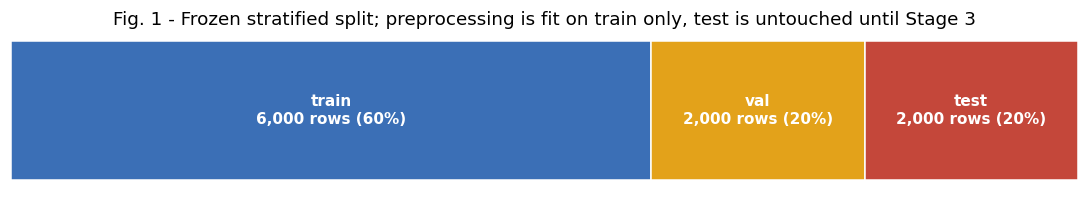

In [15]:
# Fig. 1 - Split diagram
fig, ax = plt.subplots(figsize=(10, 1.9))
left = 0

# Creates a bar for each split and labels the number and percentage of customers.
for name, color in [("train", BLUE), ("val", AMBER), ("test", RED)]:
    n = int((data["split"] == name).sum())
    ax.barh(0, n, left=left, color=color, edgecolor="white")
    ax.text(left + n / 2, 0, f"{name}\n{n:,} rows ({n/len(data):.0%})", ha="center", va="center",
            color="white", fontsize=10, fontweight="bold")
    left += n

# Removes unnecessary graph details, adds a title, and saves the figure.
ax.set_xlim(0, len(data)); ax.set_yticks([]); ax.set_xticks([]); ax.grid(False)
for s in ax.spines.values(): s.set_visible(False)
ax.set_title("Fig. 1 - Frozen stratified split; preprocessing is fit on train only, test is untouched until Stage 3")
plt.tight_layout(); plt.savefig(FIG_DIR / "fig1_split.png", bbox_inches="tight"); plt.show()

## 5. Exploratory analysis (training rows only)

The audit in Section 2 used every row because it only checks data quality. The plots below look at how the target relates to the features, and they use the **training split only**, so validation and test data cannot influence our modelling decisions.

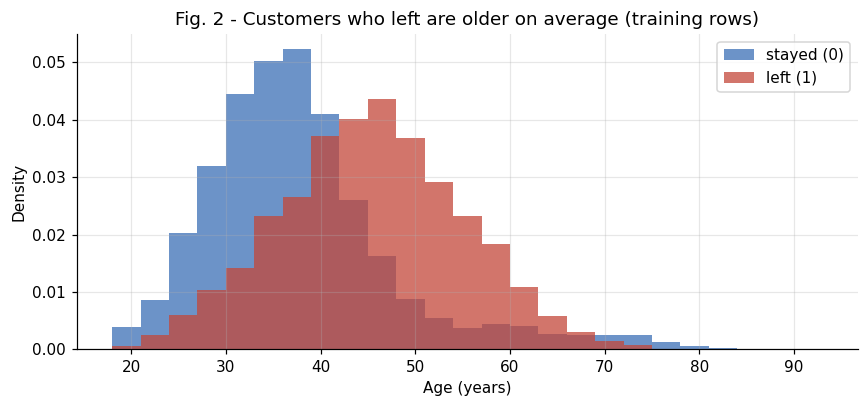

Median age (train): stayed = 36.0 | left = 45.0


In [16]:
# Fig. 2 - Age distribution for customers who stayed vs left
fig, ax = plt.subplots(figsize=(8, 3.8))
bins = np.arange(18, 94, 3)

# Plots the two age distributions on the same graph using training data only.
ax.hist(train.loc[y_train == 0, "Age"], bins=bins, alpha=0.75, color=BLUE, label="stayed (0)", density=True)
ax.hist(train.loc[y_train == 1, "Age"], bins=bins, alpha=0.75, color=RED, label="left (1)", density=True)

# Labels the graph, saves it, and prints the median age for each group.
ax.set_xlabel("Age (years)"); ax.set_ylabel("Density")
ax.set_title("Fig. 2 - Customers who left are older on average (training rows)")
ax.legend(); plt.tight_layout(); plt.savefig(FIG_DIR / "fig2_age.png", bbox_inches="tight"); plt.show()
print("Median age (train): stayed =", train.loc[y_train == 0, "Age"].median(),
      "| left =", train.loc[y_train == 1, "Age"].median())

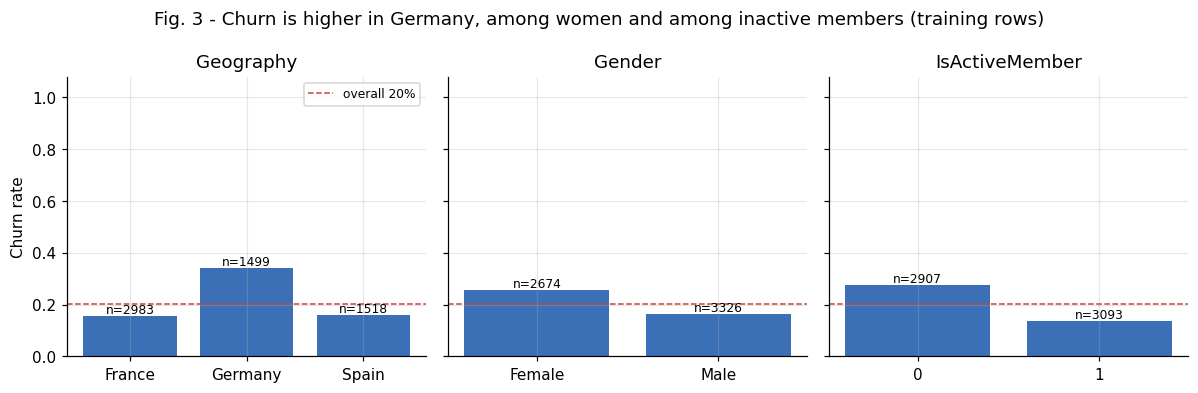

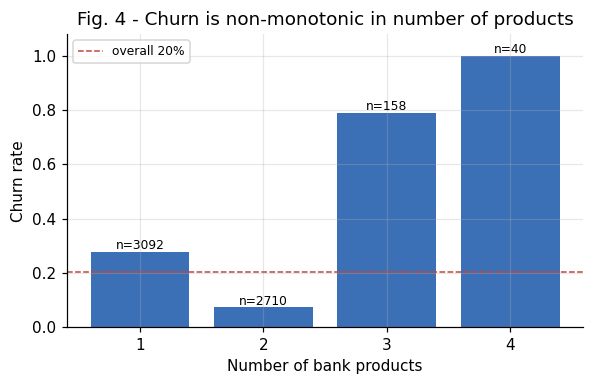

In [17]:
# Calculates the overall churn rate and creates a reusable function for churn bar charts.
# Fig. 3 and Fig. 4 - Churn rate by group
overall = y_train.mean()
def churn_bars(ax, col):
    # Groups the training data by the selected column and calculates churn rate and group size.
    g = train.groupby(col)[TARGET].agg(["mean", "size"])

    # Draws the churn rate bars and adds the overall churn rate as a reference line.
    bars = ax.bar(g.index.astype(str), g["mean"], color=BLUE)
    ax.axhline(overall, color=RED, ls="--", lw=1, label=f"overall {overall:.0%}")

    # Adds the sample size above each bar and sets the title and y-axis range.
    for b, n in zip(bars, g["size"]):
        ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.01, f"n={n}", ha="center", fontsize=8)
    ax.set_title(col); ax.set_ylim(0, 1.08)

# Figure 3 compares churn rates by geography, gender, and activity status.
fig, axes = plt.subplots(1, 3, figsize=(11, 3.6), sharey=True)
for ax, col in zip(axes, ["Geography", "Gender", "IsActiveMember"]):
    churn_bars(ax, col)
axes[0].set_ylabel("Churn rate"); axes[0].legend(loc="upper right", fontsize=8)
fig.suptitle("Fig. 3 - Churn is higher in Germany, among women and among inactive members (training rows)")
plt.tight_layout(); plt.savefig(FIG_DIR / "fig3_churn_by_group.png", bbox_inches="tight"); plt.show()

# Figure 4 uses the same function to show churn rate by number of products.
fig, ax = plt.subplots(figsize=(5.5, 3.6))
churn_bars(ax, "NumOfProducts"); ax.set_xlabel("Number of bank products"); ax.set_ylabel("Churn rate")
ax.legend(loc="upper left", fontsize=8)
ax.set_title("Fig. 4 - Churn is non-monotonic in number of products")
plt.tight_layout(); plt.savefig(FIG_DIR / "fig4_products.png", bbox_inches="tight"); plt.show()

**What the EDA tells us**
- **Fig. 2:** customers who left are noticeably older, so age is the clearest single signal.
- **Fig. 3:** churn is higher in Germany, among female customers, and among inactive members.
- **Fig. 4 (NumOfProducts):** churn is lowest at 2 products and very high at 3–4 products. The relationship is not a straight line, which is why `NumOfProducts` is one-hot encoded. The 3- and 4-product groups are small, so their rates are noisy (see the `n=` labels).

## 6. Preprocessing pipeline (fit on training data only)

| Column type | Steps |
|---|---|
| Numeric (7) | median `SimpleImputer` → `StandardScaler` |
| Categorical (Geography, Gender, NumOfProducts) | most-frequent `SimpleImputer` → `OneHotEncoder(handle_unknown="ignore")` |

The preprocessing sits **inside** each model's `Pipeline`. Calling `.fit(X_train, y_train)` learns the medians, means, standard deviations and category lists from training rows only. Validation rows are only ever transformed, never fit.

In [18]:
def make_preprocessor():
    # A function so every call builds a brand-new, UNFITTED preprocessor.
    # Each model gets its own copy, so no model reuses another's learned values.

    return ColumnTransformer([
        # ColumnTransformer = apply different cleaning steps to different columns,
        # then glue the results together side by side.
        # Each entry is (name, steps_to_apply, which_columns).

        ("num",                                       # numeric columns
         Pipeline([                                   # Pipeline runs these steps in order
             ("impute", SimpleImputer(strategy="median")),  # fill any blank with the column's median
             ("scale", StandardScaler()),             # rescale: (value - mean) / std
         ]),
         NUMERIC),                                    # apply to the 7 numeric columns

        ("cat",                                       # categorical columns
         Pipeline([
             ("impute", SimpleImputer(strategy="most_frequent")),  # fill any blank with the most common category
             ("onehot", OneHotEncoder(handle_unknown="ignore")),   # category -> 0/1 columns; unseen category -> all 0s
         ]),
         CATEGORICAL),                                # apply to Geography, Gender, NumOfProducts
    ])
    # Any column NOT listed (the dropped identifiers) is discarded automatically.

pre = make_preprocessor().fit(X_train)
# Build a preprocessor and FIT it on the training rows only.
# Fit to learn the medians, means, standard deviations and category lists.
# Validation/test rows are never shown here -> leakage control.

print("Feature matrix width after preprocessing:",
      pre.transform(X_train.head()).shape[1])
# transform(...) applies what was learned to 5 training rows.
# .head takes the 5 rows, since we don't need all 6000 to assess the amount of columns
# .shape[1] determines the number of columns(excludes rows) in the result.
# Expect 16 = 7 numeric + 3 Geography + 2 Gender + 4 NumOfProducts.

print("Scaler mean for Age is the training mean:",
      round(pre.named_transformers_["num"]["scale"].mean_[NUMERIC.index("Age")], 3),
      # pre.named_transformers_["num"]  -> the fitted numeric pipeline
      # ["scale"]                       -> the fitted StandardScaler inside it
      # .mean_                          -> array of the means it learned (one per numeric column)
      # [NUMERIC.index("Age")]          -> pick the entry that belongs to Age
      "vs", round(X_train["Age"].mean(), 3))
      # Compare with the mean computed directly from the training Age column.
      # They match (38.893), which proves the scaler learned from training rows only.


Feature matrix width after preprocessing: 16
Scaler mean for Age is the training mean: 38.893 vs 38.893


## 7. Baseline models

Every model gets the **same training rows, the same preprocessing recipe and the same metrics**, and is scored on the **validation** split. Hyperparameters are left at library defaults; tuning belongs to Stage 2.

| Model | Why it is here |
|---|---|
| Majority class | Reference point: always predicts "stayed". "Baseline improvement" is measured against it. |
| Logistic Regression | Lab 4. Linear and interpretable. |
| KNN, k = 5 | Lab 4. Non-parametric and distance-based. |
| SVM, RBF kernel | Lab 4. Non-linear decision boundary. |

**Metrics, and why accuracy is not enough.** Positive class = churned (1).
- **F1 (primary):** balances recall (catching leavers) against precision (not wasting offers on loyal customers). The majority-class model gets F1 = 0 even though its accuracy is about 80%.
- **Recall and precision:** reported separately so the trade-off is visible.
- **ROC-AUC and PR-AUC:** threshold-free ranking quality. PR-AUC is the more informative of the two when positives are rare.
- **Accuracy:** reported for completeness only.

In [19]:
models = {
    # Dictionary: {display name: unfitted model with default settings}.
    "Majority class": DummyClassifier(strategy="most_frequent"),
    # Always predicts the most common training label ("stayed"). Baseline for comparison; it learns nothing.

    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=SEED),
    # Gives each feature a weight, adds them up, turns the total into a probability.
    # max_iter=1000: 1000 learning steps so it can converge.
    # random_state=SEED: fixed seed for reproducibility.

    "KNN (k=5)": KNeighborsClassifier(n_neighbors=5),
    # Finds the 5 most similar training customers and takes a majority vote.
    # It learns nothing; it just stores the training set.

    "SVM (RBF)": SVC(kernel="rbf", random_state=SEED),
    # Finds a boundary between leavers and stayers; RBF lets the boundary be curved.
}


def size_info(model, n_features):
    # Returns a text description of how "big" a fitted model is (the Size column).

    if isinstance(model, LogisticRegression):
        # If this model is logistic regression
        return f"{model.coef_.size + model.intercept_.size} weights"
        # coef_ = 16 weights (one per feature), intercept_ = 1 -> 17 total.

    if isinstance(model, SVC):
        # If this model is the SVM...
        return f"{int(model.n_support_.sum())} support vectors x {n_features} features"
        # n_support_ = number of support vectors per class; .sum() adds them up.
        # Support vectors are training customers closest to the boundary.

    if isinstance(model, KNeighborsClassifier):
        # If this model is KNN...
        return "0 learned (stores training set)"
        # Nothing is learned; the whole training set is kept.

    return "1 (majority label)"
    # Anything else must be the dummy: it stores one label.


def scores(pipe, X):
    # Returns a continuous score per customer since ROC-AUC and PR-AUC need a
    # ranking score, not just hard 0/1 predictions.

    m = pipe.named_steps["model"]
    # Pull the model out of the pipeline (the step we named "model").

    if hasattr(m, "predict_proba") and not isinstance(m, DummyClassifier):
        # If the model can output probabilities (LR, KNN) and isn't the dummy...
        return pipe.predict_proba(X)[:, 1]
        # predict_proba gives [P(stay), P(leave)] per row; [:, 1] keeps P(leave).

    if hasattr(m, "decision_function"):
        # SVC has no probabilities by default, so use its raw score instead.
        return pipe.decision_function(X)
        # Signed distance from the boundary. Not a probability

    return np.zeros(len(X))
    # Dummy: same score (0) for everyone -> it can't rank anyone.
    # That is why its ROC-AUC is exactly 0.500.


rows, fitted = [], {}
# rows   = list that will collect one dictionary of results per model
# fitted = dictionary that will keep each trained pipeline (used by Fig. 5)

for name, model in models.items():
    # Loop over the four models one at a time.

    pipe = Pipeline([("pre", make_preprocessor()), ("model", model)])
    # Chain: fresh preprocessor -> model.
    # Calling pipe.fit(X_train, y_train) fits BOTH on training rows only.

    t0 = time.perf_counter(); pipe.fit(X_train, y_train); fit_s = time.perf_counter() - t0
    # Start stopwatch -> train the pipeline -> seconds elapsed = fit time.
    # (Includes preprocessing time, so it's indicative, not a precise benchmark.)

    t0 = time.perf_counter(); pred = pipe.predict(X_val); inf_s = time.perf_counter() - t0
    # Start stopwatch -> predict hard 0/1 labels for the 2,000 validation rows -> inference time.

    s = scores(pipe, X_val)
    # Continuous scores for validation rows (for ROC-AUC / PR-AUC).

    fitted[name] = pipe
    # Save the trained pipeline under its name for later (confusion matrices).

    n_feat = pipe.named_steps["pre"].transform(X_train.head(1)).shape[1]
    # Number of columns after preprocessing (16); needed for the SVM size text.

    rows.append({
        "Model": name,                                    # row label
        "Size": size_info(model, n_feat),                 # parameter count / size text
        "Train F1": f1_score(y_train, pipe.predict(X_train), zero_division=0),
        # F1 on the data the model learned from. Compare with Val F1 to spot overfitting.
        # zero_division=0: if the formula would divide by 0 (dummy never predicts "left"), use 0.
        "Val F1": f1_score(y_val, pred, zero_division=0),            # main metric on unseen data
        "Val recall": recall_score(y_val, pred, zero_division=0),    # % of real leavers we caught
        "Val precision": precision_score(y_val, pred, zero_division=0),  # % of flagged people who really left
        "Val ROC-AUC": roc_auc_score(y_val, s),           # ranking quality across all thresholds (0.5 = random)
        "Val PR-AUC": average_precision_score(y_val, s),  # ranking quality focused on the rare class
        "Val accuracy": accuracy_score(y_val, pred),      # % of all guesses correct (misleading here)
        "Fit time (ms)": fit_s * 1e3,                     # seconds -> milliseconds
        "Inference time on val (ms)": inf_s * 1e3,        # seconds -> milliseconds
    })

results = pd.DataFrame(rows).set_index("Model")
# Turn the list of dictionaries into a table; use the model name as the row label.

## 8. Comparison table

In [20]:
results["Val F1 gain vs majority"] = results["Val F1"] - results.loc["Majority class", "Val F1"]
# (reconstructed) New column: each model's F1 minus the dummy's F1 (which is 0).
# = "baseline improvement".

results["PR-AUC lift vs chance"] = results["Val PR-AUC"] / y_val.mean()
# New column: PR-AUC divided by the churn rate (0.204), the PR-AUC of random guessing.
# Example: 0.666 / 0.204 ~ 3.3 -> about 3x better than chance.

print("Table 3 - Baseline comparison (validation split; test split untouched)")
# Caption printed above the table.

print(f"Train rows = {len(X_train):,} | Val rows = {len(X_val):,} | "
      f"val churn rate = {y_val.mean():.1%} "           # (reconstructed)
      f"| identical split, features and metrics for every model")
# Shows the sizes and churn rate so everyone can see the comparison was fair.
# {:,} adds thousands separators; {:.1%} formats as a percentage.

fmt = {c: "{:.3f}" for c in ["Train F1", "Val F1", "Val recall", "Val precision",
                             "Val ROC-AUC", "Val PR-AUC", "Val accuracy",
                             "Val F1 gain vs majority"]}
# Dictionary: show these columns with 3 decimal places.

fmt.update({"Fit time (ms)": "{:.1f}", "Inference time on val (ms)": "{:.1f}",
            "PR-AUC lift vs chance": "{:.2f}"})
# (reconstructed) Times get 1 decimal place; the lift gets 2.

results.style.format(fmt)
# Display the table with those formats. (Last line of a cell, so it renders.)

Table 3 - Baseline comparison (validation split; test split untouched)
Train rows = 6,000 | Val rows = 2,000 | val churn rate = 20.4% | identical split, features and metrics for every model


,Size,Train F1,Val F1,Val recall,Val precision,Val ROC-AUC,Val PR-AUC,Val accuracy,Fit time (ms),Inference time on val (ms),Val F1 gain vs majority,PR-AUC lift vs chance
Model,,,,,,,,,,,,
Majority class,1 (majority label),0.000,0.000,0.000,0.000,0.500,0.204,0.796,30.5,10.7,0.000,1.00
Logistic Regression,17 weights,0.513,0.493,0.380,0.701,0.821,0.617,0.841,79.1,16.8,0.493,3.03
KNN (k=5),0 learned (stores training set),0.616,0.461,0.365,0.623,0.771,0.487,0.826,32.0,105.9,0.461,2.39
SVM (RBF),2235 support vectors x 16 features,0.585,0.533,0.387,0.854,0.821,0.666,0.862,949.5,260.4,0.533,3.26


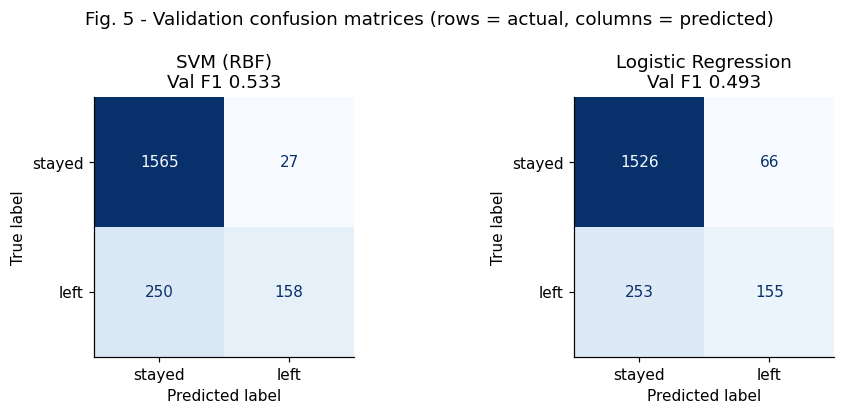

In [21]:
# Fig. 5 - validation confusion matrices for the two strongest baselines
best_two = results.drop("Majority class").sort_values("Val F1", ascending=False).index[:2]
# Drop the dummy -> sort by Val F1, highest first -> keep the names of the top 2 models.

fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
# One figure with two side-by-side plot areas.

for ax, name in zip(axes, best_two):
    # Pair each plot area with one of the two model names.

    ConfusionMatrixDisplay.from_predictions(
        y_val,                                   # the true answers
        fitted[name].predict(X_val),             # that model's guesses on validation
        display_labels=["stayed", "left"],       # axis labels instead of 0 / 1
        ax=ax,                                   # (reconstructed) draw in this plot area
        colorbar=False, cmap="Blues")            # (reconstructed) styling
    # Draws the 2x2 table: rows = actual, columns = predicted.

    ax.set_title(f"{name}\nVal F1 {results.loc[name, 'Val F1']:.3f}")
    # Title = model name plus its validation F1.

    ax.grid(False)
    # Turn off the grid lines (they clutter a matrix).

fig.suptitle("Fig. 5 - Validation confusion matrices (rows = actual, columns = predicted)")
# One overall title across both plots.

plt.tight_layout()
# Adjust spacing so labels don't overlap.

plt.savefig(FIG_DIR / "fig5_confusion.png", bbox_inches="tight")
# Save the figure as a PNG in the figures/ folder.

## 9. Conclusion and open risk

In [22]:
# Generated from the results above so the text always matches the numbers.
r = results
best = r.drop("Majority class")["Val F1"].idxmax()
print(f"Majority class: accuracy {r.loc['Majority class','Val accuracy']:.3f} but F1 = 0 and recall = 0 "
      f"(it never flags a churner)")
print(f"Best baseline by validation F1: {best}")
print(f"  F1 {r.loc[best,'Val F1']:.3f} | recall {r.loc[best,'Val recall']:.3f} | precision {r.loc[best,'Val precision']:.3f} "
      f"| ROC-AUC {r.loc[best,'Val ROC-AUC']:.3f} | PR-AUC {r.loc[best,'Val PR-AUC']:.3f}")
lr = "Logistic Regression"
print(f"Logistic Regression: F1 {r.loc[lr,'Val F1']:.3f}, recall {r.loc[lr,'Val recall']:.3f}")
print(f"Train-vs-val F1 gap for {best}: {r.loc[best,'Train F1']:.3f} vs {r.loc[best,'Val F1']:.3f}")

Majority class: accuracy 0.796 but F1 = 0 and recall = 0 (it never flags a churner)
Best baseline by validation F1: SVM (RBF)
  F1 0.533 | recall 0.387 | precision 0.854 | ROC-AUC 0.821 | PR-AUC 0.666
Logistic Regression: F1 0.493, recall 0.380
Train-vs-val F1 gap for SVM (RBF): 0.585 vs 0.533


**Concrete conclusion.** Accuracy is misleading on this data: the majority-class model scores about 80% accuracy while catching no churners at all. On validation F1 and PR-AUC, the RBF SVM is the strongest baseline and beats Logistic Regression, which is consistent with the non-linear patterns in Figs. 2 and 4. However, the two models have the same ROC-AUC. KNN is the weakest and shows the largest gap between training and validation F1, a sign of overfitting at k = 5.
**Unresolved risk to investigate next.** Every baseline uses the default 0.5 decision threshold and no correction for the 80/20 imbalance, so **recall stays low: most actual churners are still missed** (Fig. 5). In Stage 2 we will compare class weighting and a decision threshold chosen on the validation set only, alongside the tree-based models and the MLP.

## 10. Smoke test and checkpoint

In [23]:
# Quick end-to-end check the TA can run in seconds: refit Logistic Regression on 500 training rows, predict 5 validation rows.
idx = X_train.sample(500, random_state=SEED).index
smoke = Pipeline([("pre", make_preprocessor()), ("model", LogisticRegression(max_iter=1000))])
smoke.fit(X_train.loc[idx], y_train.loc[idx])
p = smoke.predict_proba(X_val.head())[:, 1]
assert p.shape == (5,) and ((p >= 0) & (p <= 1)).all()
print("Smoke test passed. P(churn) for 5 validation customers:", np.round(p, 3))

try:
    commit = subprocess.run(["git", "rev-parse", "HEAD"], capture_output=True, text=True, check=True).stdout.strip()
except Exception:
    commit = "(not a git repository here - in Colab, copy the hash from your repo's commit history on GitHub)"
print("Git commit for this checkpoint:", commit)

Smoke test passed. P(churn) for 5 validation customers: [0.23  0.182 0.121 0.068 0.472]
Git commit for this checkpoint: (not a git repository here - in Colab, copy the hash from your repo's commit history on GitHub)


In [24]:
## 11. Stage 2 — Multilayer perceptron (MLP)

from sklearn.neural_network import MLPClassifier

def mlp_param_count(mlp):
    """Learned parameters = every weight + every bias in the network."""
    return sum(W.size for W in mlp.coefs_) + sum(b.size for b in mlp.intercepts_)

def evaluate_mlp(name, pipe):
    """Fit on train, score on validation with the same metrics as the Stage 1 table."""
    t0 = time.perf_counter(); pipe.fit(X_train, y_train); fit_s = time.perf_counter() - t0
    t0 = time.perf_counter(); pred = pipe.predict(X_val); inf_s = time.perf_counter() - t0
    p = pipe.predict_proba(X_val)[:, 1]
    mlp = pipe.named_steps["model"]
    return {"Model": name, "Size": f"{mlp_param_count(mlp):,} weights + biases",
            "Train F1": f1_score(y_train, pipe.predict(X_train), zero_division=0),
            "Val F1": f1_score(y_val, pred, zero_division=0),
            "Val recall": recall_score(y_val, pred, zero_division=0),
            "Val precision": precision_score(y_val, pred, zero_division=0),
            "Val ROC-AUC": roc_auc_score(y_val, p), "Val PR-AUC": average_precision_score(y_val, p),
            "Val accuracy": accuracy_score(y_val, pred),
            "Fit time (ms)": fit_s * 1e3, "Inference time on val (ms)": inf_s * 1e3, "Seed": SEED}

# First MLP: one hidden layer of 32 neurons, library defaults otherwise (no tuning yet)
mlp_first = Pipeline([("pre", make_preprocessor()),
                      ("model", MLPClassifier(hidden_layer_sizes=(32,), max_iter=500, random_state=SEED))])
row = evaluate_mlp("MLP (32), untuned", mlp_first)
display(pd.DataFrame([row]).set_index("Model").round(3))
print("Epochs trained:", mlp_first.named_steps["model"].n_iter_)

,Size,Train F1,Val F1,Val recall,Val precision,Val ROC-AUC,Val PR-AUC,Val accuracy,Fit time (ms),Inference time on val (ms),Seed
Model,,,,,,,,,,,
"MLP (32), untuned",577 weights + biases,0.651,0.577,0.468,0.752,0.845,0.682,0.86,5439.341,20.803,3000


Epochs trained: 356


In [ ]:
# %% Cell 1: HPO contract (defined before any trial runs)
import itertools, json, datetime
import joblib                                                  # saves/loads trained models to a file
from sklearn.tree import DecisionTreeClassifier                # one tree: a flowchart of yes/no questions
from sklearn.ensemble import RandomForestClassifier            # many trees that vote together

MODEL_DIR = Path("models"); MODEL_DIR.mkdir(exist_ok=True)     # folder for saved models (no error if it exists)

HPO_OBJECTIVE = "maximise Val F1 (churn class, default 0.5 threshold)"
HPO_TIEBREAK  = ["higher Val PR-AUC", "fewer tree nodes (simpler model)"]
HPO_DATA      = "fit on TRAIN rows only, scored on VAL rows only; test split never used"
HPO_STOPPING  = "exhaustive grid: stop when every combination has been run once. No early stopping, no re-runs."

FIXED_DT = dict(criterion="gini", random_state=SEED)           # settings we don't tune (seed makes runs repeatable)
GRID_DT = {                                                    # settings we do tune: values to try for each
    "max_depth":        [3, 5, 7, 10, None],                   # how many questions deep a tree may go (None = no limit)
    "min_samples_leaf": [1, 5, 20, 50],                        # minimum customers per final box (bigger = simpler tree)
    "class_weight":     [None, "balanced"],                    # "balanced" makes missing a churner cost more
}
FIXED_RF = dict(max_features="sqrt", n_jobs=-1, random_state=SEED)   # n_jobs=-1 uses all CPU cores
GRID_RF = {
    "n_estimators":     [100, 300],                            # number of trees in the forest
    "max_depth":        [5, 8, 12, None],
    "min_samples_leaf": [1, 5, 20],
    "class_weight":     [None, "balanced"],
}
# Number of trials = multiply the option counts, e.g. DT: 5 x 4 x 2 = 40
n_dt = int(np.prod([len(v) for v in GRID_DT.values()]))
n_rf = int(np.prod([len(v) for v in GRID_RF.values()]))

print("HPO CONTRACT")
print("  Objective :", HPO_OBJECTIVE)
print("  Tie-break :", HPO_TIEBREAK)
print("  Data      :", HPO_DATA)
print("  Stopping  :", HPO_STOPPING)
print(f"  Decision Tree grid ({n_dt} trials): {GRID_DT}")
print(f"  Random Forest grid ({n_rf} trials): {GRID_RF}")
print(f"  Total budget: {n_dt + n_rf} trials, each fitted once on train and scored once on val")

# %% Cell 2: Helpers
def tree_nodes(model):
    """Total nodes = parameter count for tree models (a node is one question or one final answer box)."""
    if isinstance(model, DecisionTreeClassifier):              # single tree: read its node count directly
        return model.tree_.node_count
    return sum(t.tree_.node_count for t in model.estimators_)  # forest: add up the nodes of every tree inside it

def tree_size_text(model):
    if isinstance(model, DecisionTreeClassifier):
        return f"{model.tree_.node_count} nodes (depth {model.get_depth()})"   # depth = longest chain of questions
    return f"{len(model.estimators_)} trees, {tree_nodes(model):,} nodes"

def evaluate(name, pipe, fit_s):
    """One results row, same columns as the Stage 1 table."""
    t0 = time.perf_counter(); pred = pipe.predict(X_val); inf_s = time.perf_counter() - t0  # stopwatch around predicting
    s = scores(pipe, X_val)                                    # churn probability per customer (needed for ROC/PR-AUC)
    return {"Model": name, "Size": tree_size_text(pipe.named_steps["model"]),   # named_steps["model"] = the tree/forest inside the pipeline
            "Train F1": f1_score(y_train, pipe.predict(X_train), zero_division=0),  # score on data it learned from
            "Val F1": f1_score(y_val, pred, zero_division=0),                       # score on unseen data (the main one)
            "Val recall": recall_score(y_val, pred, zero_division=0),
            "Val precision": precision_score(y_val, pred, zero_division=0),
            "Val ROC-AUC": roc_auc_score(y_val, s),
            "Val PR-AUC": average_precision_score(y_val, s),
            "Val accuracy": accuracy_score(y_val, pred),
            "Fit time (ms)": fit_s * 1e3, "Inference time on val (ms)": inf_s * 1e3}  # seconds -> milliseconds

def run_grid(label, model_cls, fixed, grid):
    """Try every combination: fresh preprocessor + model, fit on train, score on val."""
    out = []                                                   # one result row per trial goes in here
    # itertools.product gives every combination of the setting values, e.g. (3,1,None), (3,1,"balanced"), (3,5,None), ...
    for i, combo in enumerate(itertools.product(*grid.values()), start=1):   # enumerate numbers the trials 1, 2, 3, ...
        params = dict(zip(grid.keys(), combo))                 # pair names with values, e.g. {"max_depth": 3, "min_samples_leaf": 1, ...}
        pipe = Pipeline([("pre", make_preprocessor()),         # fresh, unfitted preprocessor each trial (no leakage)
                         ("model", model_cls(**fixed, **params))])   # ** unpacks both dicts into keyword arguments
        t0 = time.perf_counter(); pipe.fit(X_train, y_train); fit_s = time.perf_counter() - t0   # train on TRAIN only, timed
        row = evaluate(label, pipe, fit_s)                     # score this trial on validation
        row.update({"trial": i, "params": params,              # remember which settings produced this row
                    "nodes": tree_nodes(pipe.named_steps["model"])})
        out.append(row)
    return pd.DataFrame(out)                                   # list of rows -> table

RANK_COLS, RANK_ASC = ["Val F1", "Val PR-AUC", "nodes"], [False, False, True]  # the contract's ranking rule
# False = highest first (F1, PR-AUC); True = lowest first (fewer nodes wins a tie)
def pick_best(trials):
    return trials.sort_values(RANK_COLS, ascending=RANK_ASC).iloc[0]   # sort by the rule, take the top row

# %% Cell 3: Run the grid searches
t0 = time.perf_counter()
trials_dt = run_grid("Decision Tree", DecisionTreeClassifier, FIXED_DT, GRID_DT)   # all 40 trials
hpo_dt_s = time.perf_counter() - t0                            # total search time = computational cost of HPO

t0 = time.perf_counter()
trials_rf = run_grid("Random Forest", RandomForestClassifier, FIXED_RF, GRID_RF)   # all 48 trials
hpo_rf_s = time.perf_counter() - t0

print(f"Decision Tree: {len(trials_dt)} trials in {hpo_dt_s:.1f} s")
print(f"Random Forest: {len(trials_rf)} trials in {hpo_rf_s:.1f} s")
print(f"Total HPO cost: {hpo_dt_s + hpo_rf_s:.1f} s")

# %% Cell 4: Table 4 - top trials
def show_trials(trials, title, k=8):
    t = trials.copy()                                          # copy so the original table isn't changed
    # turn each settings dict into readable text like "max_depth=10, min_samples_leaf=20, ..."
    t["config"] = t["params"].map(lambda p: ", ".join(f"{a}={b}" for a, b in p.items()))
    t["gap"] = t["Train F1"] - t["Val F1"]                     # overfitting gap
    t = t.sort_values(RANK_COLS, ascending=RANK_ASC)           # best trial first
    cols = ["trial", "config", "Train F1", "Val F1", "gap", "Val recall", "Val precision",
            "Val PR-AUC", "nodes", "Fit time (ms)"]
    print(title)
    # .style.format sets decimal places; .hide(axis="index") removes the row-number column
    display(t[cols].head(k).style.format({"Train F1": "{:.3f}", "Val F1": "{:.3f}", "gap": "{:.3f}",
        "Val recall": "{:.3f}", "Val precision": "{:.3f}", "Val PR-AUC": "{:.3f}",
        "nodes": "{:,}", "Fit time (ms)": "{:.0f}"}).hide(axis="index"))

show_trials(trials_dt, f"Table 4a - Decision Tree: top 8 of {len(trials_dt)} trials (validation split)")
show_trials(trials_rf, f"Table 4b - Random Forest: top 8 of {len(trials_rf)} trials (validation split)")

# %% Cell 5: Fig. 6 - all trials
fig, axes = plt.subplots(1, 2, figsize=(11, 4))                # two side-by-side plots
for trials, color, label in [(trials_dt, BLUE, "Decision Tree"), (trials_rf, RED, "Random Forest")]:
    b = pick_best(trials)                                      # the selected trial for this model
    axes[0].plot(trials["trial"], trials["Val F1"], "o", color=color, alpha=0.6, label=label)   # one dot per trial
    axes[0].plot(b["trial"], b["Val F1"], "*", color="black", ms=14)                            # star = selected trial
    axes[1].scatter(trials["Train F1"], trials["Val F1"], color=color, alpha=0.6, label=label)  # train vs val for every trial
axes[0].set_xlabel("Trial number"); axes[0].set_ylabel("Validation F1")
axes[0].set_title("Validation F1 of every trial (star = selected)"); axes[0].legend()
lim = [0.3, 1.02]
axes[1].plot(lim, lim, "k--", lw=1)                            # dashed line where train = val (no overfitting)
axes[1].set_xlim(lim); axes[1].set_ylim(0.3, 0.7)
axes[1].set_xlabel("Train F1"); axes[1].set_ylabel("Validation F1")
axes[1].set_title("Train vs validation F1 (below dashed line = overfit)"); axes[1].legend()
fig.suptitle("Fig. 6 - Grid-search trials for the tree-based models (validation evidence only)")
plt.tight_layout(); plt.savefig(FIG_DIR / "fig6_hpo_trials.png", bbox_inches="tight")

# %% Cell 6: Refit the winning configuration of each model
fitted_trees, tree_rows, best_params = {}, [], {}              # trained pipelines, result rows, winning settings
for label, cls, fixed, trials in [("Decision Tree", DecisionTreeClassifier, FIXED_DT, trials_dt),
                                  ("Random Forest", RandomForestClassifier, FIXED_RF, trials_rf)]:
    best = pick_best(trials)                                   # winning trial for this model
    name = f"{label} (tuned)"
    best_params[name] = dict(best["params"])
    pipe = Pipeline([("pre", make_preprocessor()), ("model", cls(**fixed, **best["params"]))])   # fresh pipeline, winning settings
    t0 = time.perf_counter(); pipe.fit(X_train, y_train); fit_s = time.perf_counter() - t0       # same seed, so it matches the trial
    fitted_trees[name] = pipe
    tree_rows.append(evaluate(name, pipe, fit_s))
    print(f"{name}: selected trial {int(best['trial'])} -> {best['params']}")

results_trees = pd.DataFrame(tree_rows).set_index("Model")     # model name becomes the row label

# %% Cell 7: Table 5 - all models in one table
parts = [results[results_trees.columns], results_trees]        # Stage 1 baselines + tuned trees (same columns)
if "results_mlp" in globals():                                 # only if a teammate defined an MLP results table
    parts.append(results_mlp[results_trees.columns])
combined = pd.concat(parts)                                    # stack them into one table
combined["Val F1 gain vs majority"] = combined["Val F1"] - combined.loc["Majority class", "Val F1"]   # improvement over the lazy model
combined["PR-AUC lift vs chance"] = combined["Val PR-AUC"] / y_val.mean()                             # times better than random (churn rate)

print("Table 5 - All models, same split, same preprocessing, same metrics (validation split; test untouched)")
print(f"Train rows = {len(X_train):,} | Val rows = {len(X_val):,} | val churn rate = {y_val.mean():.1%}")
fmt = {c: "{:.3f}" for c in ["Train F1", "Val F1", "Val recall", "Val precision", "Val ROC-AUC",
                             "Val PR-AUC", "Val accuracy", "Val F1 gain vs majority"]}   # 3 decimal places for scores
fmt.update({"Fit time (ms)": "{:.1f}", "Inference time on val (ms)": "{:.1f}", "PR-AUC lift vs chance": "{:.2f}"})
combined.style.format(fmt)                                     # last line of the cell, so the table displays

# %% Cell 8: Fig. 7 - confusion matrices of the tuned trees
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
for ax, name in zip(axes, fitted_trees):                       # one plot per tuned tree model
    # 2x2 table of right/wrong guesses: true validation answers vs this model's predictions
    ConfusionMatrixDisplay.from_predictions(y_val, fitted_trees[name].predict(X_val), ax=ax,
                                            display_labels=["stayed", "left"], colorbar=False, cmap="Blues")
    ax.set_title(f"{name}\nVal F1 {results_trees.loc[name, 'Val F1']:.3f}"); ax.grid(False)
fig.suptitle("Fig. 7 - Validation confusion matrices (rows = actual, columns = predicted)")
plt.tight_layout(); plt.savefig(FIG_DIR / "fig7_tree_confusion.png", bbox_inches="tight")

# %% Cell 9: Fig. 8 - top features of the tuned random forest
rf_pipe = fitted_trees["Random Forest (tuned)"]
# the preprocessor knows its 16 output column names (like "num__Age"); split("__", 1)[1] drops the "num__"/"cat__" prefix
names = [n.split("__", 1)[1] for n in rf_pipe.named_steps["pre"].get_feature_names_out()]
# feature_importances_ = how much each feature helped the forest's splits; keep the 10 largest
imp = pd.Series(rf_pipe.named_steps["model"].feature_importances_, index=names).sort_values().tail(10)
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.barh(imp.index, imp.values, color=BLUE)                     # horizontal bar chart
ax.set_xlabel("Impurity-based importance (training data)")
ax.set_title("Fig. 8 - Top 10 features, tuned Random Forest"); ax.grid(axis="y", alpha=0)
plt.tight_layout(); plt.savefig(FIG_DIR / "fig8_rf_importance.png", bbox_inches="tight")

# %% Cell 10: Pick the finalist w/ validation evidence only
fitted_all = {**fitted, **fitted_trees}                        # merge the two dicts of trained pipelines into one
fitted_all.update(globals().get("fitted_mlp", {}))             # add the MLP pipeline if defined, otherwise add nothing

cand = combined.drop("Majority class").copy()                  # the dummy is only a reference, not a candidate
cand["Train-Val F1 gap"] = cand["Train F1"] - cand["Val F1"]
# rank: highest Val F1, then highest PR-AUC, then smallest overfitting gap
ranking = cand.sort_values(["Val F1", "Val PR-AUC", "Train-Val F1 gap"], ascending=[False, False, True])
print("Table 6 - Ranking by validation evidence")
display(ranking[["Val F1", "Val PR-AUC", "Val recall", "Val precision", "Train-Val F1 gap",
                 "Fit time (ms)", "Inference time on val (ms)"]].style.format("{:.3f}"))
FINALIST = ranking.index[0]                                    # top-ranked model's name
print("Finalist:", FINALIST)

# %% Cell 11: Checkpoint (fitted preprocessing + model + config)
def checkpoint(name, pipe):
    """The pipeline holds the fitted preprocessor, so one file saves preprocessing + model."""
    slug = name.lower().replace(" ", "_").replace("(", "").replace(")", "")   # "Random Forest (tuned)" -> "random_forest_tuned"
    joblib.dump(pipe, MODEL_DIR / f"{slug}.joblib", compress=3)               # compress=3 makes the file smaller
    row = combined.loc[name]                                   # this model's row in the comparison table
    cfg = {"model": name, "seed": SEED,
           "hyperparameters": pipe.named_steps["model"].get_params(),         # every setting of the model
           "numeric_features": NUMERIC, "categorical_features": CATEGORICAL,
           "split_file": "data/split_assignment.csv (train/val/test by CustomerId, frozen)",
           "selection_rule": "max Val F1; tie-break Val PR-AUC, then train-val gap",
           "validation_metrics": {k: float(row[k]) for k in
                                  ["Val F1", "Val recall", "Val precision", "Val ROC-AUC", "Val PR-AUC", "Val accuracy"]},
           "size": row["Size"],
           "library_versions": {"python": platform.python_version(), "numpy": np.__version__,
                                "pandas": pd.__version__, "scikit-learn": sklearn.__version__},   # for reproducing the environment
           "created": datetime.datetime.now().isoformat(timespec="seconds")}
    # default=str converts anything that isn't JSON-friendly into text
    (MODEL_DIR / f"{slug}_config.json").write_text(json.dumps(cfg, indent=2, default=str))
    return slug

# save both tuned trees plus the finalist; dict.fromkeys removes duplicates (keeps order) if the finalist is one of the trees
saved = {n: checkpoint(n, fitted_all[n]) for n in dict.fromkeys([*fitted_trees, FINALIST])}
finalist_slug = saved[FINALIST]
print("Saved:", sorted(p.name for p in MODEL_DIR.iterdir()))

# %% Cell 12: Smoke test - reload the finalist and confirm it reproduces its validation F1
reloaded = joblib.load(MODEL_DIR / f"{finalist_slug}.joblib")  # load it back from disk, as in a fresh session
f1_check = f1_score(y_val, reloaded.predict(X_val))
# assert stops with an error if this is false: the reloaded F1 must match the table (difference < 0.000000001)
assert abs(f1_check - combined.loc[FINALIST, "Val F1"]) < 1e-9, "reloaded model disagrees with saved results"
print(f"Smoke test passed: reloaded {FINALIST} gives Val F1 = {f1_check:.3f} (matches Table 5)")

### Contribution log (Stage 1)
| Member | What they did this stage |
|---|---|
| Isabelle Trudeau |0-2|
| Marin Seeley |3-5|
| Nora Rawson |6-8|
| Lucas Sousa |9-10|

